[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_gpd/BA_L4_gpd.ipynb)

# BA_L4_gpd: Quantile Function with Generalised Pareto Tails

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Quantile function of a Gaussian body (standard deviation 3 basis points) spliced at the 5% and 95% levels with generalised Pareto (GPD) tails, for symmetric and asymmetric tail parameters, on a normal-quantile scale. Analytical illustration, no data.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

A distributional forecast of the deviation can be written as a quantile function: a body $Q^B(u)$ between the levels $\tau_L$ and $\tau_U$, and generalised Pareto distribution (GPD) tails joined smoothly at those levels:

$$ Q(u) = \begin{cases} z_L - \dfrac{\beta_L}{\xi_L}\Big[\big(\tfrac{u}{\tau_L}\big)^{-\xi_L} - 1\Big], & u < \tau_L \\[2mm] Q^B(u), & \tau_L \leq u \leq \tau_U \\[1mm] z_U + \dfrac{\beta_U}{\xi_U}\Big[\big(\tfrac{1-u}{1-\tau_U}\big)^{-\xi_U} - 1\Big], & u > \tau_U \end{cases} $$

with $z_L = Q^B(\tau_L)$, $\beta_L = \tau_L\,Q^{B\prime}(\tau_L)$, and symmetrically for the upper tail. For $\xi \geq 1/2$ the tail has infinite variance.

Illustration: a Gaussian body with standard deviation (sd) 3 basis points (bp), splice points at 5% and 95%, and three choices of the tail parameters. The horizontal axis is on the normal-quantile scale, on which the Gaussian is a straight line.

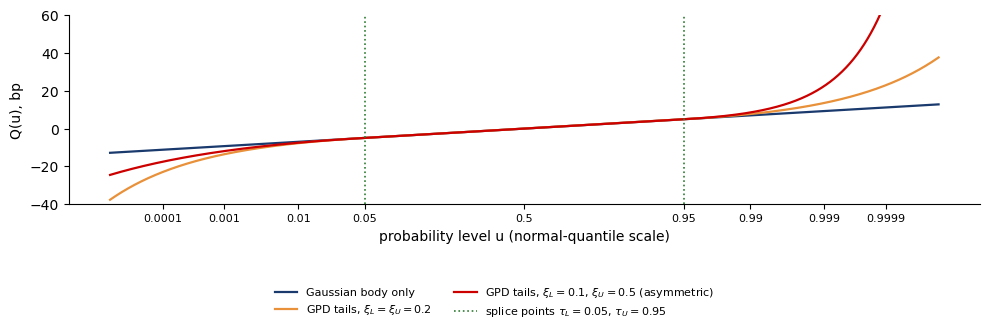

In [5]:
tl, tu, s_b = 0.05, 0.95, 3.0
QB = lambda uu: s_b * stats.norm.ppf(uu)
dQ = lambda uu: s_b / stats.norm.pdf(stats.norm.ppf(uu))


def Qspl(uu, xl, xu):
    """Gaussian body with GPD tails below tau_L and above tau_U."""
    uu = np.asarray(uu, dtype=float)
    zl, zu = QB(tl), QB(tu); bl, bu = tl * dQ(tl), (1 - tu) * dQ(tu)
    out = QB(np.clip(uu, tl, tu))
    m1, m2 = uu < tl, uu > tu
    out[m1] = zl - bl / xl * ((uu[m1] / tl) ** (-xl) - 1)
    out[m2] = zu + bu / xu * (((1 - uu[m2]) / (1 - tu)) ** (-xu) - 1)
    return out


uu = np.concatenate([np.logspace(-5, np.log10(0.5), 1000), 1 - np.logspace(np.log10(0.5), -5, 1000)[1:]])
zu_ = stats.norm.ppf(uu)
fig, ax = plt.subplots(figsize=(10, 3.3))
ax.plot(zu_, QB(uu), color=BLUE, lw=1.6, label='Gaussian body only')
ax.plot(zu_, Qspl(uu, 0.2, 0.2), color=BTC, lw=1.6, label=r'GPD tails, $\xi_L = \xi_U = 0.2$')
ax.plot(zu_, Qspl(uu, 0.1, 0.5), color=RED, lw=1.6, label=r'GPD tails, $\xi_L = 0.1$, $\xi_U = 0.5$ (asymmetric)')
for t_ in (tl, tu):
    ax.axvline(stats.norm.ppf(t_), color=GREEN, ls=':', lw=1.2, label=(r'splice points $\tau_L = 0.05$, $\tau_U = 0.95$' if t_ == tl else None))
ax.set_xticks(stats.norm.ppf([1e-4, 1e-3, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999, 0.9999]))
ax.set_xticklabels(['0.0001', '0.001', '0.01', '0.05', '0.5', '0.95', '0.99', '0.999', '0.9999'], fontsize=8)
ax.set_xlabel('probability level u (normal-quantile scale)'); ax.set_ylabel('Q(u), bp'); ax.set_ylim(-40, 60)
save(fig, 'ba_l4_gpd', 0.2, ncol=2)

## Key numbers

In [6]:
rows = {'Gaussian body only': {'0.1% quantile (bp)': QB(0.001), '99.9% quantile (bp)': QB(0.999)}}
for xl, xu in [(0.2, 0.2), (0.1, 0.5)]:
    rows[f'GPD tails, xi_L = {xl}, xi_U = {xu}'] = {'0.1% quantile (bp)': Qspl([0.001], xl, xu)[0], '99.9% quantile (bp)': Qspl([0.999], xl, xu)[0]}
pd.DataFrame(rows).T.round(1)

,0.1% quantile (bp),99.9% quantile (bp)
Gaussian body only,-9.3,9.3
"GPD tails, xi_L = 0.2, xi_U = 0.2",-13.6,13.6
"GPD tails, xi_L = 0.1, xi_U = 0.5",-11.9,22.6


**How to read it:** a heavier upper tail ($\xi_U = 0.5$) more than doubles the 99.9% quantile of the Gaussian, while the lower tail with $\xi_L = 0.1$ stays close to it: separate tail parameters let USDC and USDT depegs differ.